# Eksperimen: Split Data Mana yang Lebih Baik?

**Pertanyaan:** untuk dataset stroke (5.109 pasien, 249 stroke), split mana yang memberi hasil lebih baik dan lebih bisa dipercaya?

| Skema | Latih | Validasi | Uji | Cara kerja |
|---|---|---|---|---|
| **A. 70/15/15** | 70% | 15% | 15% | latih → pilih threshold di validasi → uji |
| **B. 80/20 → (80/20)** | 80% | 16% | 4% | 80/20, lalu bagian 20% dipecah lagi 80/20 jadi validasi & uji |
| C. *pembanding: notebook sekarang* | 80% | 20% (dari latih) | 20% | latih 60% → pilih threshold → **latih ulang di 80%** → uji |

**Aturan supaya adil:** model **sama persis** (`LogisticRegression` dari `model_lr.py`, lr 0,1, 2000 epoch, class weight), aturan threshold sama (tertinggi dengan recall validasi ≥ 0,80), dan seed acak sama. **Yang berbeda hanya cara split.**

**Kenapa tidak cukup sekali jalan?** Hasil satu kali split bergantung pada pasien mana yang *kebetulan* masuk ke data uji. Jadi eksperimen diulang dengan **100 seed** berbeda, lalu dilihat **rata-rata** (seberapa bagus) dan **simpangan/rentangnya** (seberapa bisa dipercaya).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from model_lr import Preprocessor, LogisticRegression     # model yang sama dengan notebook utama

TARGET = 'stroke'
df = pd.read_csv('healthcare-dataset-stroke-data.csv').drop(columns=['id'])
df = df[df['gender'] != 'Other'].reset_index(drop=True)
print(df.shape, '| stroke:', df[TARGET].sum())

(5109, 11) | stroke: 249


In [2]:
def split_stratified(y, fracs, seed):
    # Bagi indeks per kelas sesuai proporsi fracs, misal (0.7, 0.15, 0.15)
    rng = np.random.default_rng(seed)
    bagian = [[] for _ in fracs]
    for kelas in np.unique(y):
        idx = rng.permutation(np.where(y == kelas)[0])
        batas = np.round(np.cumsum(fracs)[:-1] * len(idx)).astype(int)
        for i, potong in enumerate(np.split(idx, batas)):
            bagian[i].extend(potong)
    return [np.array(b) for b in bagian]

def evaluasi(y, skor, t):
    pred = (skor >= t).astype(int)
    tp, fp = np.sum((y == 1) & (pred == 1)), np.sum((y == 0) & (pred == 1))
    fn = np.sum((y == 1) & (pred == 0))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f2 = 5 * precision * recall / (4 * precision + recall) if precision + recall else 0.0
    rank = np.argsort(np.argsort(skor)) + 1                              # AUC (Mann-Whitney)
    n1, n0 = y.sum(), len(y) - y.sum()
    auc = (rank[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    return {'recall': recall, 'precision': precision, 'f2': f2, 'auc': auc}

def latih(data):
    prep = Preprocessor().fit(data)
    model = LogisticRegression(lr=0.1, epochs=2000, class_weight=True).fit(prep.transform(data).values, data[TARGET].values)
    return prep, model

def pilih_threshold(prep, model, val):
    skor, y = model.predict_proba(prep.transform(val).values), val[TARGET].values
    for t in np.round(np.arange(0.95, 0.04, -0.01), 2):                  # dari tinggi ke rendah
        if evaluasi(y, skor, t)['recall'] >= 0.80:
            return t
    return 0.05

In [3]:
def jalankan(skema, seed):
    y = df[TARGET].values
    if skema == 'A. 70/15/15':
        i_tr, i_va, i_te = split_stratified(y, (0.70, 0.15, 0.15), seed)
        train, val, test = df.iloc[i_tr], df.iloc[i_va], df.iloc[i_te]
        prep, model = latih(train)
        t = pilih_threshold(prep, model, val)
    elif skema == 'B. 80/16/4':
        i_tr, i_sisa = split_stratified(y, (0.80, 0.20), seed)
        sisa = df.iloc[i_sisa]
        i_va, i_te = split_stratified(sisa[TARGET].values, (0.80, 0.20), seed)   # 20% dipecah lagi 80/20
        train, val, test = df.iloc[i_tr], sisa.iloc[i_va], sisa.iloc[i_te]
        prep, model = latih(train)
        t = pilih_threshold(prep, model, val)
    else:  # C. notebook sekarang
        i_tr, i_te = split_stratified(y, (0.80, 0.20), seed)
        train, test = df.iloc[i_tr], df.iloc[i_te]
        i_fit, i_va = split_stratified(train[TARGET].values, (0.75, 0.25), seed)
        t = pilih_threshold(*latih(train.iloc[i_fit]), train.iloc[i_va])
        prep, model = latih(train)                                        # latih ulang di seluruh 80%
    hasil = evaluasi(test[TARGET].values, model.predict_proba(prep.transform(test).values), t)
    return {'skema': skema, 'seed': seed, 'threshold': t, 'stroke_di_uji': int(test[TARGET].sum()),
            'pasien_di_uji': len(test), **hasil}

SKEMA = ['A. 70/15/15', 'B. 80/16/4', 'C. 80/20 + val dari latih']

## 1. Kalau hanya dijalankan SEKALI (seed 42)
Ini cara yang biasa dilakukan, dan cara inilah yang bisa menipu.

In [4]:
sekali = pd.DataFrame([jalankan(s, 42) for s in SKEMA]).set_index('skema')
sekali[['pasien_di_uji', 'stroke_di_uji', 'threshold', 'recall', 'precision', 'f2', 'auc']].round(3)

,pasien_di_uji,stroke_di_uji,threshold,recall,precision,f2,auc
skema,,,,,,,
A. 70/15/15,766,37,0.49,0.865,0.137,0.419,0.847
B. 80/16/4,204,10,0.62,0.600,0.150,0.375,0.818
C. 80/20 + val dari latih,1022,50,0.39,0.900,0.111,0.373,0.851


**Kalau hanya melihat tabel ini**, kesimpulannya "C paling bagus (recall 0,90), B paling jelek (0,60)". Tapi lihat jumlah kasus stroke di data uji B: **hanya 10**. Recall 0,60 artinya 6 dari 10, dan selisih 1–2 pasien saja sudah mengubah angkanya 10–20 poin.
Perhatikan juga: hasil skema C di sini (recall 0,90) **berbeda** dengan notebook utama (0,78), padahal modelnya sama. Penyebabnya, pasien yang masuk data uji berbeda. Inilah bukti bahwa satu kali jalan tidak cukup untuk membandingkan split.

## 2. Diulang 100 kali dengan seed berbeda

In [5]:
hasil = pd.DataFrame([jalankan(s, seed) for seed in range(100) for s in SKEMA])

ringkasan = hasil.groupby('skema').agg(
    stroke_di_uji=('stroke_di_uji', 'mean'),
    recall_rata2=('recall', 'mean'), recall_std=('recall', 'std'),
    recall_min=('recall', 'min'), recall_max=('recall', 'max'),
    f2_rata2=('f2', 'mean'), f2_std=('f2', 'std'),
    precision_rata2=('precision', 'mean'), auc_rata2=('auc', 'mean'), auc_std=('auc', 'std'))
ringkasan.round(3)

,stroke_di_uji,recall_rata2,recall_std,recall_min,recall_max,f2_rata2,f2_std,precision_rata2,auc_rata2,auc_std
skema,,,,,,,,,,
A. 70/15/15,37.0,0.800,0.080,0.541,0.973,0.394,0.032,0.131,0.838,0.023
B. 80/16/4,10.0,0.773,0.150,0.400,1.000,0.400,0.074,0.138,0.837,0.051
C. 80/20 + val dari latih,50.0,0.796,0.087,0.500,0.960,0.397,0.029,0.134,0.840,0.021


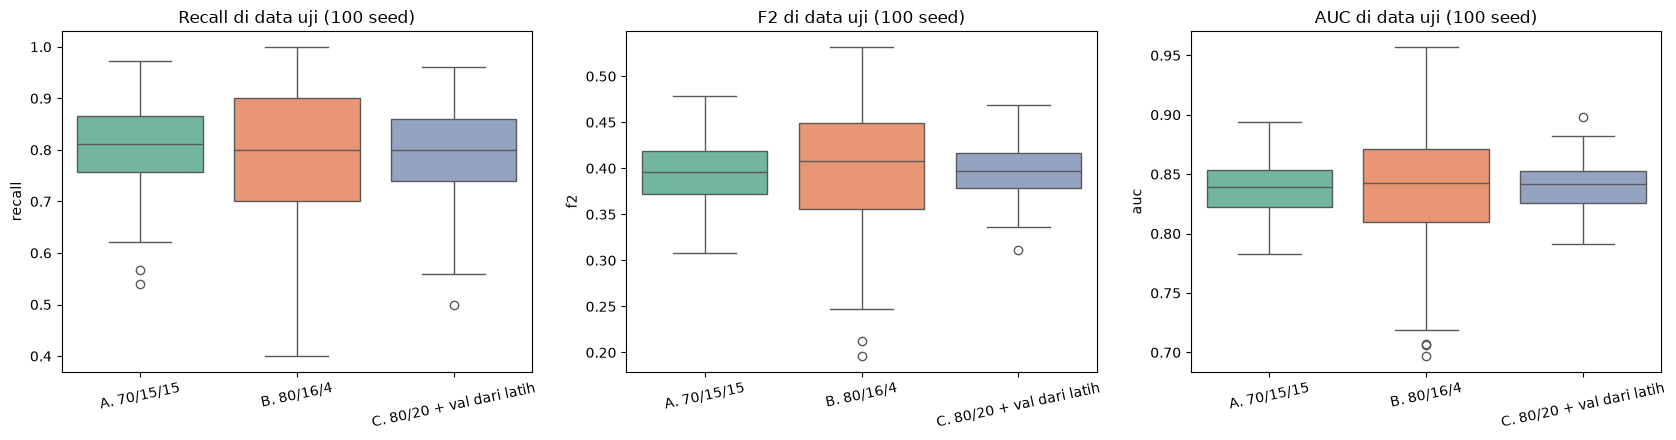

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (kolom, judul) in zip(axes, [('recall', 'Recall di data uji'), ('f2', 'F2 di data uji'), ('auc', 'AUC di data uji')]):
    sns.boxplot(data=hasil, x='skema', y=kolom, hue='skema', ax=ax, palette='Set2', legend=False)
    ax.set_title(f'{judul} (100 seed)')
    ax.set_xlabel('')
    ax.set_ylabel(kolom)
    ax.tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.show()

In [7]:
# Seberapa sering hasilnya "menipu"? Hitung berapa persen seed yang recall-nya meleset > 0,15 dari rata-rata skemanya
for s in SKEMA:
    r = hasil.loc[hasil['skema'] == s, 'recall']
    meleset = (np.abs(r - r.mean()) > 0.15).mean() * 100
    print(f'{s:28} rentang recall {r.min():.2f}–{r.max():.2f} | meleset > 0,15 dari rata-rata: {meleset:.0f}% seed')

A. 70/15/15                  rentang recall 0.54–0.97 | meleset > 0,15 dari rata-rata: 5% seed
B. 80/16/4                   rentang recall 0.40–1.00 | meleset > 0,15 dari rata-rata: 31% seed
C. 80/20 + val dari latih    rentang recall 0.50–0.96 | meleset > 0,15 dari rata-rata: 7% seed


## Kesimpulan

**1. Rata-rata performanya hampir sama.** Recall ±0,77–0,80, F2 ±0,39–0,40, dan AUC ±0,84 di ketiga skema. **Cara split tidak membuat model lebih pintar.** Modelnya sama, dan beda 70% vs 80% data latih hampir tidak terasa.

**2. Yang berbeda jauh adalah seberapa bisa DIPERCAYA angkanya.**

| | A. 70/15/15 | B. 80/16/4 | C. notebook |
|---|---|---|---|
| Stroke di data uji | 37 | **10** | 50 |
| Simpangan recall | 0,08 | **0,15** (2×) | 0,09 |
| Rentang recall | 0,54–0,97 | **0,40–1,00** | 0,50–0,96 |
| Seed yang meleset > 0,15 | 5% | **31%** | 7% |
| Simpangan AUC | 0,023 | **0,051** (2×) | 0,021 |

Dengan skema **B**, recall yang kamu laporkan bisa jatuh di mana saja antara 0,40 dan 1,00, tergantung keberuntungan. Hampir 1 dari 3 kali hasilnya meleset jauh dari kemampuan model yang sebenarnya. Data uji 4% (±10 kasus stroke) **terlalu kecil** untuk dataset ini.

**3. A dan C sama-sama stabil, dan selisihnya tidak bermakna.** C sedikit lebih stabil di F2 dan AUC karena data ujinya lebih besar. Tapi A sedikit lebih stabil di recall, karena di C threshold dipilih dengan model yang dilatih di 60% data lalu dipakai untuk model yang dilatih ulang di 80%, sehingga ada sedikit ketidakcocokan.

**Keputusan:** untuk dataset ini, **pakai 70/15/15**. Stabilitasnya setara dengan C, dan kodenya lebih sederhana (tanpa latih ulang). **Hindari 80/16/4**: bukan karena modelnya lebih jelek, tapi karena angka hasilnya tidak bisa dipercaya.

**Pelajaran umum:** pilih rasio split berdasarkan **jumlah kasus minoritas di data uji**, bukan jumlah baris total. Dan kalau membandingkan dua cara, jalankan dengan **banyak seed**, bukan sekali.